In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency,kruskal
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OrdinalEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier


pd.set_option('display.max_columns', None) #Displays all columns

### Load the dataset

In [3]:
financial_data = pd.read_excel(
    r"C:\Users\HP\Desktop\financess\Data\finaccess2024_datasprint.xlsx"
)

financial_data.head()

,county,location_type,Sex,Age,household_size,education_level,marital_status,monthly_income,Savings_formal,Savings_informal,Loan_formal,Loan_informal,defaulted,formal_service_use,mobile_money_access,barriers_mobile_money,mobile_ownership_1,experienced_shock,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,financial_status,fl_score,prodsum1,barriers_bank,has_disability
0,Garissa,Urban,Female,26-35,5,Completed technical training after secondary s...,Married/Living with partner,30000,Non-usage,Non-usage,Non-usage,Usage,No,Usage,Yes,0,Yes,No,Yes,Yes,Yes,Yes,No,Stayed the same,All correct,3,NaN,Without Disability
1,Garissa,Urban,Female,Above 55,11,"""None """,Married/Living with partner,10000,Non-usage,Non-usage,Non-usage,Non-usage,No,Usage,Yes,0,Yes,No,No,No,Yes,No,No,Worsened,Two correct,1,Affordability,Without Disability
2,Busia,Urban,Female,26-35,2,"""Primary completed""",Divorced/separated,3000,Usage,Usage,Non-usage,Non-usage,No,Usage,Yes,0,Yes,Yes,Yes,No,No,No,No,Improved,All correct,5,Affordability,Without Disability
3,Kiambu,Urban,Male,18-25,1,"""Some secondary""",Single/Never Married,10000,Usage,Non-usage,Usage,Usage,Yes,Usage,Yes,0,Yes,No,No,No,No,Yes,No,Improved,All correct,4,Affordability,Without Disability
4,Murang'a,Urban,Female,18-25,1,Some technical training after secondary school,Single/Never Married,10000,Usage,Non-usage,Usage,Non-usage,No,Usage,Yes,0,Yes,No,Yes,Yes,Yes,Yes,Yes,Improved,All correct,5,NaN,Without Disability


### Step 3: Checking the Overview of the dataset

In [4]:
def basic_checks(data):
    print("-"*35, "Duplicates", "-"*35)
    print(data.duplicated().sum())

    print("-"*35, "Shape", "-"*35)
    print(data.shape)

    print("-"*35, "Missing Values", "-"*35)
    print(data.isnull().sum())

    print("-"*35, "Data Types", "-"*35)
    print(data.dtypes)

    print("-"*35, "Summary Statistics(Categorical)", "-"*35)
    print(display(data.describe(include='object').T))   

    print("-"*35, "Summary Statistics(Numerical)", "-"*35)
    print(display(data.describe().T))

basic_checks(financial_data)

----------------------------------- Duplicates -----------------------------------
5
----------------------------------- Shape -----------------------------------
(20871, 28)
----------------------------------- Missing Values -----------------------------------
county                      0
location_type               0
Sex                         0
Age                         0
household_size              0
education_level             0
marital_status              0
monthly_income              0
Savings_formal              0
Savings_informal            0
Loan_formal                 0
Loan_informal               0
defaulted                   0
formal_service_use          0
mobile_money_access         0
barriers_mobile_money       0
mobile_ownership_1          0
experienced_shock           0
nfhi_11                     0
nfhi_12                     0
nfhi_13                     0
accessto_13k_1month         0
not_difficult               0
financial_status            0
fl_score          

C:\Users\HP\AppData\Local\Temp\ipykernel_28836\1843632636.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(display(data.describe(include='object').T))


,count,unique,top,freq
county,20871,47,Meru,637
location_type,20871,2,Rural,13549
Sex,20871,2,Female,12326
Age,20871,6,26-35,5361
education_level,20871,13,"""Secondary completed """,4113
marital_status,20871,6,Married/Living with partner,11432
Savings_formal,20871,2,Non-usage,11635
Savings_informal,20871,2,Non-usage,16031
Loan_formal,20871,2,Non-usage,12340
Loan_informal,20871,2,Non-usage,12604


None
----------------------------------- Summary Statistics(Numerical) -----------------------------------


,count,mean,std,min,25%,50%,75%,max
household_size,20871.0,4.215946,2.512658,1.0,2.0,4.0,6.0,20.0
monthly_income,20871.0,9702.774280,15423.366592,100.0,2500.0,5000.0,10000.0,200000.0
prodsum1,20871.0,3.936563,3.227992,0.0,1.0,3.0,6.0,22.0


None


#### Categorical Entries

In [5]:
categorical_columns = financial_data.select_dtypes(include=('object')).columns.to_list()

print(categorical_columns)

for col in categorical_columns:
    print("-"*35, col.upper(), "-"*35)
    print(financial_data[col].unique())
    print(financial_data[col].nunique())

['county', 'location_type', 'Sex', 'Age', 'education_level', 'marital_status', 'Savings_formal', 'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted', 'formal_service_use', 'mobile_money_access', 'barriers_mobile_money', 'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12', 'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'financial_status', 'fl_score', 'barriers_bank', 'has_disability']
----------------------------------- COUNTY -----------------------------------
<StringArray>
[        'Garissa',           'Busia',          'Kiambu',        'Murang'a',
          'Kilifi',            'Meru',          'Kisumu',         'Baringo',
          'Isiolo',            'Embu',         'Mombasa', 'Elgeyo-Marakwet',
         'Homabay',          'Migori',           'Siaya',      'West Pokot',
           'Nyeri',           'Bomet',         'Makueni',     'Uasin Gishu',
         'Bungoma',          'Nakuru',        'Kakamega',           'Kwale',
           'Kitui',         'M

C:\Users\HP\AppData\Local\Temp\ipykernel_28836\1541465182.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = financial_data.select_dtypes(include=('object')).columns.to_list()


2
----------------------------------- DEFAULTED -----------------------------------
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
2
----------------------------------- FORMAL_SERVICE_USE -----------------------------------
<StringArray>
['Usage', 'Non-usage']
Length: 2, dtype: str
2
----------------------------------- MOBILE_MONEY_ACCESS -----------------------------------
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
2
----------------------------------- BARRIERS_MOBILE_MONEY -----------------------------------
[0 'Eligibility' 'Phone ownership' 'Line blocked' 'Other' 'Affordability'
 'Relevance/Suitability' 'Awareness' 'Service quality' 'Trust']
10
----------------------------------- MOBILE_OWNERSHIP_1 -----------------------------------
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
2
----------------------------------- EXPERIENCED_SHOCK -----------------------------------
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
2
----------------------------------- NFHI_11 ----

['household_size', 'monthly_income', 'prodsum1']


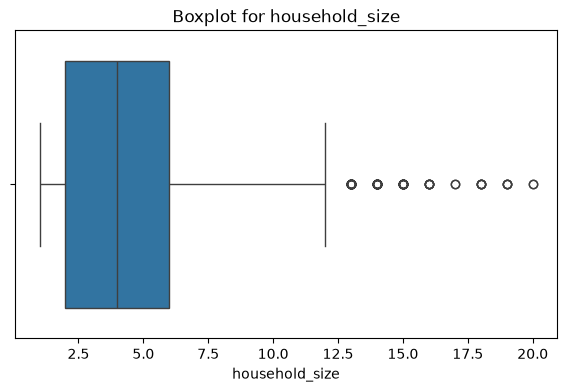

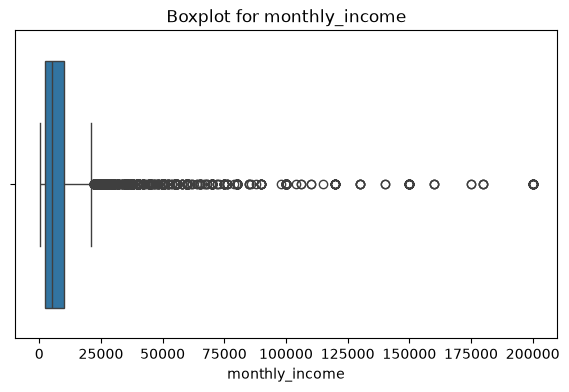

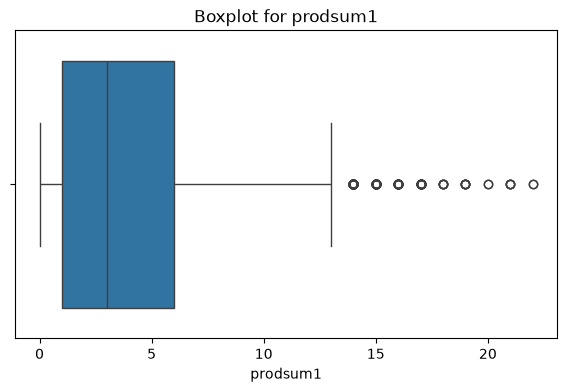

In [6]:
num_cols = financial_data.select_dtypes(include=('int', 'float')).columns.to_list()

print(num_cols)

for col in num_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=financial_data, x=col)
    plt.title(f"Boxplot for {col}")
    plt.xlabel(col)
    plt.ylabel("")
    plt.show()



## Step 3: Data Cleaning

_Drop the duplicates_

In [7]:
financial_data.drop_duplicates(inplace=True)

#Check if dropped
financial_data.duplicated().sum()

np.int64(0)

### Cleaning categotical columns
1. Education

_Remove_ 'Completed technical training after secondary school' and replace with 'Technical Training and drop invalid education level

In [8]:
mapping = {'Completed technical training after secondary school': 'Technical training',
           'Some technical training after secondary school': 'Technical Training',
           '"Primary completed"': 'Primary',
           '"Some secondary"': 'Secondary Incomplete',
           '"Secondary completed "': 'Secondary',
           '"Some primary "': 'Primary Incomplete',
           'Some university': 'University Incomplete',
           '"University completed "': 'University',
           '"Refused to Answer (DO NOT READ OUT)"': '',
           '"None "': 'None',
           '"Other (Specify) "': ''
           }

financial_data['education_level'] = financial_data['education_level'].replace(mapping)


# Verify
print(financial_data['education_level'].unique())
print(financial_data['education_level'].isnull().sum())

['Technical training' 'None' 'Primary' 'Secondary Incomplete'
 'Technical Training' 'Secondary' 'Primary Incomplete' 'University' ''
 'University Incomplete' 95 '"Don\'t know (DO NOT READ OUT)"']
0


In [9]:
financial_data = financial_data[~financial_data['education_level'].str.contains('DO NOT READ OUT', na=False)]

In [10]:
financial_data['education_level'].unique()

array(['Technical training', 'None', 'Primary', 'Secondary Incomplete',
       'Technical Training', 'Secondary', 'Primary Incomplete',
       'University', '', 'University Incomplete', 95], dtype=object)

In [11]:
financial_data.drop(financial_data[financial_data['education_level']==""].index, inplace=True)

In [12]:
financial_data['education_level'].unique()

array(['Technical training', 'None', 'Primary', 'Secondary Incomplete',
       'Technical Training', 'Secondary', 'Primary Incomplete',
       'University', 'University Incomplete', 95], dtype=object)

__Cleaning Marital Status Ctegories__

In [13]:
(financial_data['marital_status'].value_counts() / len(financial_data)) * 100

marital_status
Married/Living with partner           54.767726
Single/Never Married                  27.647538
Widowed                               10.705211
Divorced/separated                     6.836378
Don't know   (DO NOT READ OUT)         0.023970
Refused to Answer(DO NOT READ OUT)     0.019176
Name: count, dtype: float64

__Drop Categories(Refused to Answer(DO NOT READ OUT, Don't know   (DO NOT READ OUT))__

In [14]:
financial_data.drop(financial_data[(financial_data['marital_status']=="Don't know   (DO NOT READ OUT)") & (financial_data['marital_status']== "Refused to Answer(DO NOT READ OUT)")].index, inplace=True)

In [15]:
mapping = {"Don't know   (DO NOT READ OUT)": '',
           "Refused to Answer(DO NOT READ OUT)": ''}

financial_data['marital_status'] = financial_data['marital_status'].replace(mapping)


In [16]:
financial_data['marital_status'].unique()

<StringArray>
['Married/Living with partner',          'Divorced/separated',
        'Single/Never Married',                     'Widowed',
                            '']
Length: 5, dtype: str

In [17]:
financial_data.drop(financial_data[financial_data['marital_status']==""].index, inplace=True)

In [18]:
financial_data.columns

Index(['county', 'location_type', 'Sex', 'Age', 'household_size',
       'education_level', 'marital_status', 'monthly_income', 'Savings_formal',
       'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted',
       'formal_service_use', 'mobile_money_access', 'barriers_mobile_money',
       'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12',
       'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'financial_status',
       'fl_score', 'prodsum1', 'barriers_bank', 'has_disability'],
      dtype='str')

__Cleaning barriers_mobile_money category__

In [19]:
mapping = {0: 'None'}

financial_data['barriers_mobile_money'] = financial_data['barriers_mobile_money'].replace(mapping)

In [20]:
financial_data['barriers_mobile_money'].unique()

array(['None', 'Eligibility', 'Phone ownership', 'Line blocked', 'Other',
       'Affordability', 'Relevance/Suitability', 'Awareness',
       'Service quality', 'Trust'], dtype=object)

__Handling Missing Values__

In [21]:
(financial_data.isnull().sum() / len(financial_data)) * 100

county                    0.000000
location_type             0.000000
Sex                       0.000000
Age                       0.000000
household_size            0.000000
education_level           0.000000
marital_status            0.000000
monthly_income            0.000000
Savings_formal            0.000000
Savings_informal          0.000000
Loan_formal               0.000000
Loan_informal             0.000000
defaulted                 0.000000
formal_service_use        0.000000
mobile_money_access       0.000000
barriers_mobile_money     0.000000
mobile_ownership_1        0.000000
experienced_shock         0.000000
nfhi_11                   0.000000
nfhi_12                   0.000000
nfhi_13                   0.000000
accessto_13k_1month       0.000000
not_difficult             0.000000
financial_status          0.000000
fl_score                  0.000000
prodsum1                  0.000000
barriers_bank            27.482014
has_disability            0.000000
dtype: float64

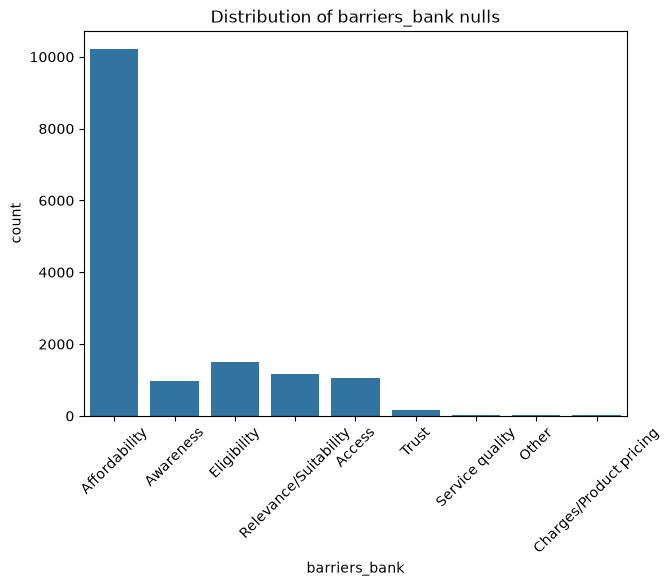

In [22]:
plt.figure(figsize=(7, 5))
sns.countplot(financial_data, x="barriers_bank")
plt.title("Distribution of barriers_bank nulls")
plt.xlabel('barriers_bank')
plt.xticks(rotation=45)
plt.show()

In [23]:
# Fill Nulls
barriers_bank_mode = financial_data['barriers_bank'].mode()[0]
print(barriers_bank_mode)

financial_data = financial_data.fillna(value={'barriers_bank': barriers_bank_mode})

# Verify
(financial_data.isnull().sum() / len(financial_data)) * 100

Affordability


county                   0.0
location_type            0.0
Sex                      0.0
Age                      0.0
household_size           0.0
education_level          0.0
marital_status           0.0
monthly_income           0.0
Savings_formal           0.0
Savings_informal         0.0
Loan_formal              0.0
Loan_informal            0.0
defaulted                0.0
formal_service_use       0.0
mobile_money_access      0.0
barriers_mobile_money    0.0
mobile_ownership_1       0.0
experienced_shock        0.0
nfhi_11                  0.0
nfhi_12                  0.0
nfhi_13                  0.0
accessto_13k_1month      0.0
not_difficult            0.0
financial_status         0.0
fl_score                 0.0
prodsum1                 0.0
barriers_bank            0.0
has_disability           0.0
dtype: float64

### step 5: EDA and Hypothesis Test 

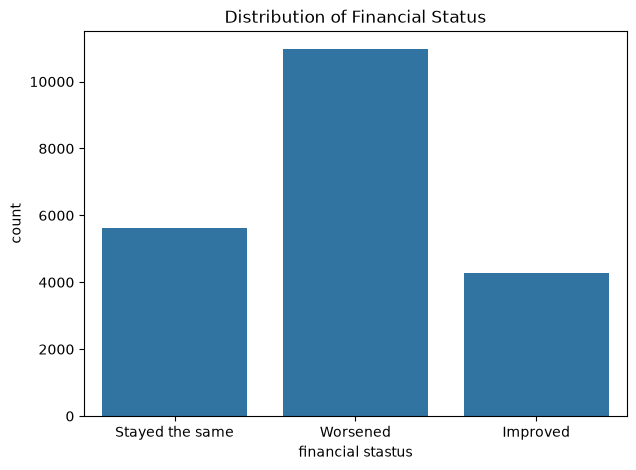

In [24]:
financial_data['financial_status'].unique()

plt.figure(figsize=(7, 5))

sns.countplot(financial_data, x= 'financial_status')
plt.title('Distribution of Financial Status')
plt.xlabel('financial stastus')
plt.ylabel('count')
plt.show()

**financial status in comparison  to age**

Text(0, 0.5, 'Financial Status')

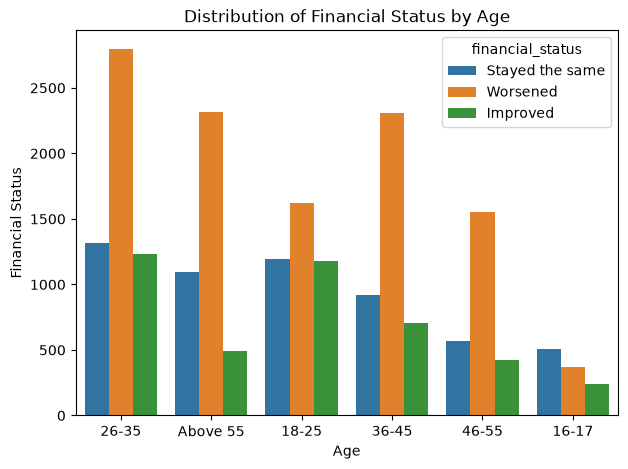

In [25]:
plt.figure(figsize=(7, 5))
sns.countplot(financial_data, x= 'Age',hue ='financial_status')
plt.title('Distribution of Financial Status by Age')
plt.xlabel('Age')
plt.ylabel('Financial Status')

**financial status in comparison to educational level**

Text(0, 0.5, 'Financial Status')

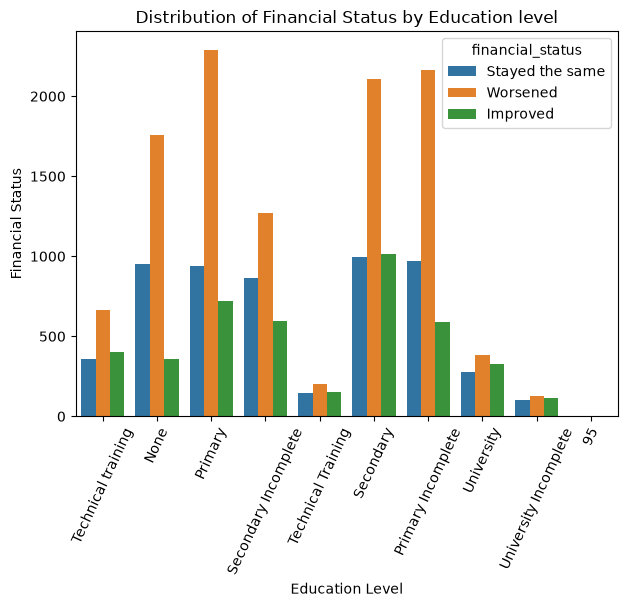

In [26]:
plt.figure(figsize=(7, 5))
sns.countplot(financial_data, x= 'education_level',hue ='financial_status')
plt.title('Distribution of Financial Status by Education level')
plt.xlabel('Education Level')
plt.xticks(rotation=65)
plt.ylabel('Financial Status')

**comparison between diability and and the financial_status**

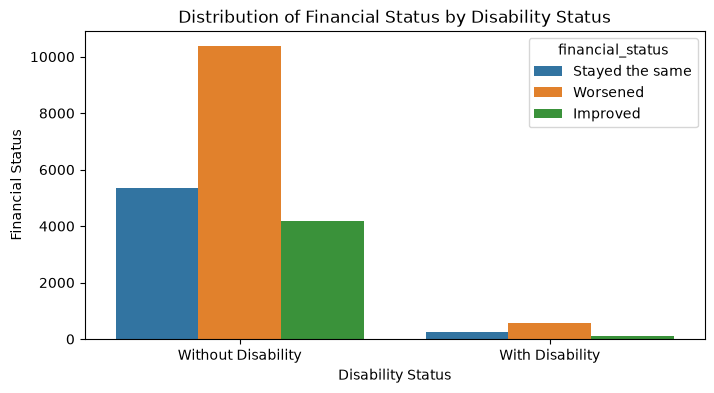

In [27]:
plt.figure(figsize=(8, 4))
sns.countplot(financial_data, x='has_disability',hue = 'financial_status')
plt.title('Distribution of Financial Status by Disability Status')
plt.xlabel('Disability Status')
plt.ylabel('Financial Status')
plt.show()

**Monthly income compared to savings type((formal))**

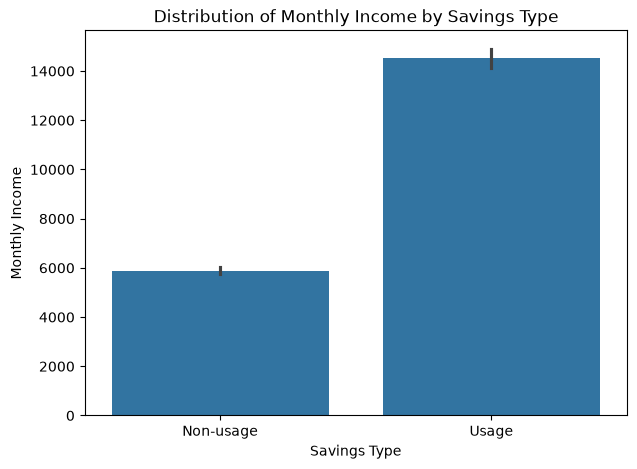

In [28]:
plt.figure(figsize=(7, 5))
sns.barplot(financial_data, x= 'Savings_formal', y='monthly_income')
plt.title('Distribution of Monthly Income by Savings Type')
plt.xlabel('Savings Type')
plt.ylabel('Monthly Income')
plt.show()



### Hypothesis Test
**categorical column vs target(categorical)**

In [29]:
categorical_columns.remove('financial_status')

In [30]:
categorical_columns

['county',
 'location_type',
 'Sex',
 'Age',
 'education_level',
 'marital_status',
 'Savings_formal',
 'Savings_informal',
 'Loan_formal',
 'Loan_informal',
 'defaulted',
 'formal_service_use',
 'mobile_money_access',
 'barriers_mobile_money',
 'mobile_ownership_1',
 'experienced_shock',
 'nfhi_11',
 'nfhi_12',
 'nfhi_13',
 'accessto_13k_1month',
 'not_difficult',
 'fl_score',
 'barriers_bank',
 'has_disability']

In [31]:
for column in categorical_columns:
    print("-"*40, column.upper(),"-"*40)

    h0 = f'There is no association between {column} and financial_status"'
    h1 = f'There is an assocition between {column} and financial_status"'

    contingency_table = pd.crosstab(financial_data[column], financial_data['financial_status'])
    chi2_stats,p_value, dof, expected = chi2_contingency(contingency_table)

    if p_value <= 0.05:
        print('Reject the null hypothesis')

    else:
        print('Fail to reject the null hypothesis')

---------------------------------------- COUNTY ----------------------------------------
Reject the null hypothesis
---------------------------------------- LOCATION_TYPE ----------------------------------------
Reject the null hypothesis
---------------------------------------- SEX ----------------------------------------
Reject the null hypothesis
---------------------------------------- AGE ----------------------------------------
Reject the null hypothesis
---------------------------------------- EDUCATION_LEVEL ----------------------------------------
Reject the null hypothesis
---------------------------------------- MARITAL_STATUS ----------------------------------------
Reject the null hypothesis
---------------------------------------- SAVINGS_FORMAL ----------------------------------------
Reject the null hypothesis
---------------------------------------- SAVINGS_INFORMAL ----------------------------------------
Reject the null hypothesis
------------------------------------

**Numerical column vs Target(categorical)**

In [32]:
numerical_cols = financial_data.select_dtypes(include=['int','float']).columns.to_list()

In [33]:
numerical_cols

['household_size', 'monthly_income', 'prodsum1']

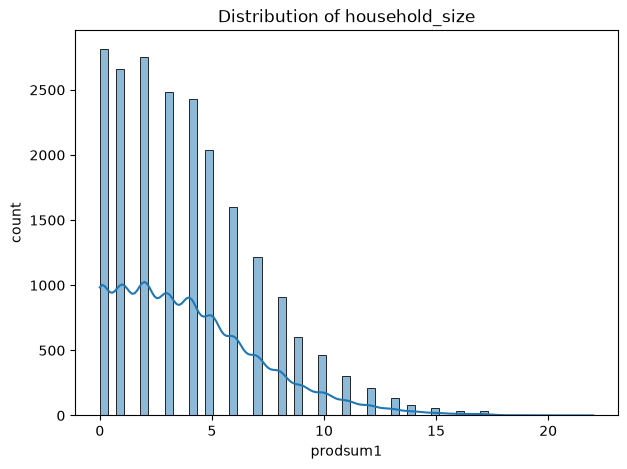

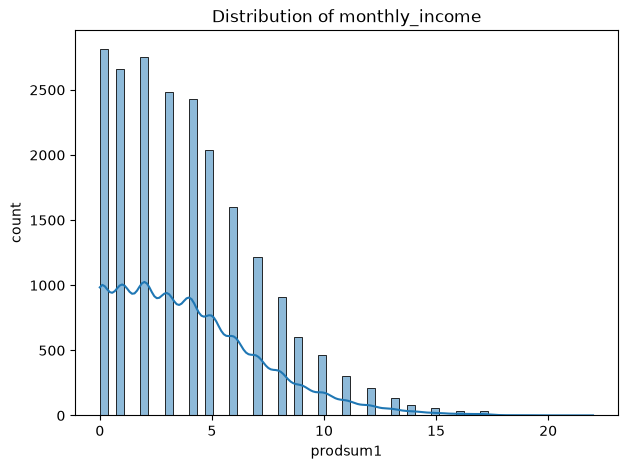

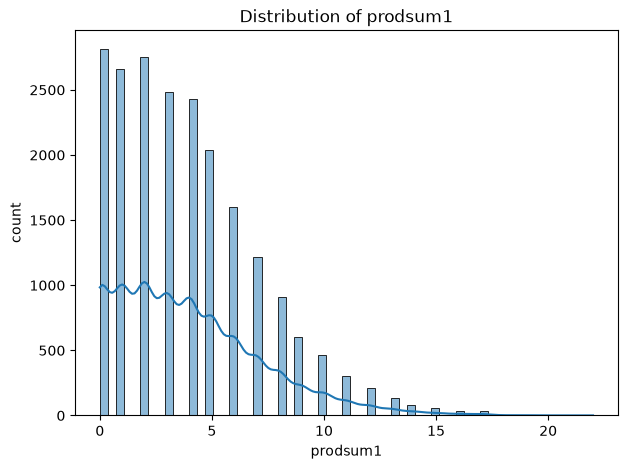

In [34]:
#checking for normal distribution

for cols in numerical_cols:
    plt.figure(figsize=(7, 5))
    sns.histplot(financial_data[col], kde=True)
    plt.title('Distribution of ' + cols )
    plt.xlabel(col)
    plt.ylabel('count')
    plt.show()

In [35]:
financial_data.groupby('financial_status')['prodsum1'].var()

financial_status
Improved           12.176858
Stayed the same     9.802476
Worsened            9.740139
Name: prodsum1, dtype: float64

**kruskal-wallis**

In [36]:
for column in numerical_cols:
    print('-'*40, column.upper(), '-'*40)

    h0 = f'There is no difference in the distribution of' + column + 'across financial_status'
    h1 = f'There atleast one difference in the distribution of' + column + 'across financial_status'

    groups = [group[column].values for name, group in financial_data.groupby('financial_status')]

    stat,p_value = kruskal(*groups)

    if p_value <= 0.05:
        print('Reject the null hypothesis')

    else:
        print('Fail to reject the null hypothesis')




    

---------------------------------------- HOUSEHOLD_SIZE ----------------------------------------
Reject the null hypothesis
---------------------------------------- MONTHLY_INCOME ----------------------------------------
Reject the null hypothesis
---------------------------------------- PRODSUM1 ----------------------------------------
Reject the null hypothesis


**Numerical columns vs numerical**

In [37]:
correlation = financial_data[numerical_cols].corr(method = 'spearman')
correlation

,household_size,monthly_income,prodsum1
household_size,1.000000,-0.116565,-0.157055
monthly_income,-0.116565,1.000000,0.433420
prodsum1,-0.157055,0.433420,1.000000


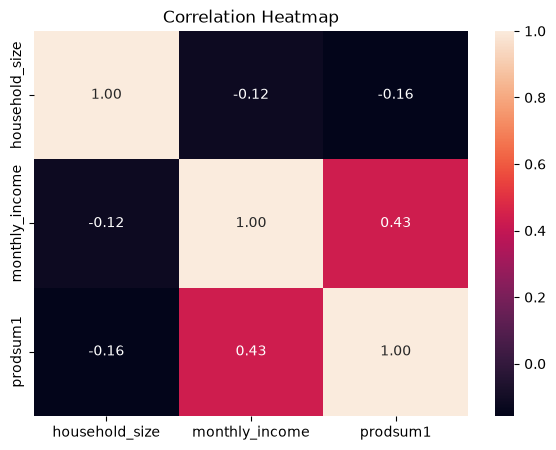

In [38]:
plt.figure(figsize=(7,5))
sns.heatmap(correlation, annot=True, fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### Splitting features and target

In [39]:
X = financial_data.drop(columns=['financial_status'])
y = financial_data['financial_status']

In [40]:
financial_data.columns

print(X.shape, y.shape)

(20850, 27) (20850,)


### Training Model

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

### Pre-processing(Encoding and scaling)


In [42]:
X_train.columns

Index(['county', 'location_type', 'Sex', 'Age', 'household_size',
       'education_level', 'marital_status', 'monthly_income', 'Savings_formal',
       'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted',
       'formal_service_use', 'mobile_money_access', 'barriers_mobile_money',
       'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12',
       'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'fl_score',
       'prodsum1', 'barriers_bank', 'has_disability'],
      dtype='str')

In [43]:
cat_cols = X_train.select_dtypes(include=['object']).columns.to_list()
cat_cols.remove('Age')

C:\Users\HP\AppData\Local\Temp\ipykernel_28836\3919622649.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=['object']).columns.to_list()


In [44]:
# one hot encoding categorical columns
# X_train



X_test = pd.get_dummies(X_test, columns=cat_cols, dtype='int', drop_first=True)

#X_test

In [45]:
print(X_train.columns)

Index(['county', 'location_type', 'Sex', 'Age', 'household_size',
       'education_level', 'marital_status', 'monthly_income', 'Savings_formal',
       'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted',
       'formal_service_use', 'mobile_money_access', 'barriers_mobile_money',
       'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12',
       'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'fl_score',
       'prodsum1', 'barriers_bank', 'has_disability'],
      dtype='str')


In [46]:
X_train.head()

,county,location_type,Sex,Age,household_size,education_level,marital_status,monthly_income,Savings_formal,Savings_informal,Loan_formal,Loan_informal,defaulted,formal_service_use,mobile_money_access,barriers_mobile_money,mobile_ownership_1,experienced_shock,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,fl_score,prodsum1,barriers_bank,has_disability
13958,Nyamira,Urban,Female,Above 55,1,Secondary,Married/Living with partner,3000,Non-usage,Non-usage,Usage,Usage,No,Usage,Yes,None,Yes,Yes,Yes,Yes,Yes,No,No,Two correct,3,Affordability,With Disability
6905,Kilifi,Urban,Female,26-35,3,Technical training,Married/Living with partner,5000,Non-usage,Non-usage,Usage,Usage,Yes,Usage,Yes,None,Yes,No,No,No,No,No,No,All correct,4,Affordability,Without Disability
560,Nandi,Urban,Female,36-45,6,Technical training,Married/Living with partner,2000,Usage,Non-usage,Usage,Usage,Yes,Usage,Yes,None,Yes,Yes,Yes,No,No,Yes,No,Two correct,7,Affordability,Without Disability
20171,Bungoma,Rural,Female,Above 55,2,Secondary Incomplete,Widowed,5000,Non-usage,Non-usage,Non-usage,Usage,Yes,Usage,Yes,None,Yes,Yes,No,No,No,No,No,All correct,1,Affordability,Without Disability
18645,Nakuru,Urban,Male,36-45,5,Secondary,Married/Living with partner,17000,Usage,Non-usage,Usage,Non-usage,No,Usage,Yes,None,Yes,No,Yes,Yes,Yes,Yes,No,All correct,5,Affordability,Without Disability


In [47]:
age_order = ['16-17', '18-25', '26-35', '36-45', '46-55', 'Above 55']
encoder = OrdinalEncoder(categories=[age_order])
#X_train

X_train[['Age']] = encoder.fit_transform(X_train[['Age']])

#X_tes9t
X_test[['Age']] = encoder.transform(X_test[['Age']])

In [48]:
financial_data['Age'].unique()

<StringArray>
['26-35', 'Above 55', '18-25', '36-45', '46-55', '16-17']
Length: 6, dtype: str

In [49]:
le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

In [50]:
#Scaling
num_cols = financial_data.select_dtypes(include=['int','float']).columns.to_list()

In [51]:
scaler = RobustScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

X_test[num_cols] = scaler.transform(X_test[num_cols])

In [52]:
X_train.head()

,county,location_type,Sex,Age,household_size,education_level,marital_status,monthly_income,Savings_formal,Savings_informal,Loan_formal,Loan_informal,defaulted,formal_service_use,mobile_money_access,barriers_mobile_money,mobile_ownership_1,experienced_shock,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,fl_score,prodsum1,barriers_bank,has_disability
13958,Nyamira,Urban,Female,5.0,-0.75,Secondary,Married/Living with partner,-0.266667,Non-usage,Non-usage,Usage,Usage,No,Usage,Yes,None,Yes,Yes,Yes,Yes,Yes,No,No,Two correct,0.0,Affordability,With Disability
6905,Kilifi,Urban,Female,2.0,-0.25,Technical training,Married/Living with partner,0.000000,Non-usage,Non-usage,Usage,Usage,Yes,Usage,Yes,None,Yes,No,No,No,No,No,No,All correct,0.2,Affordability,Without Disability
560,Nandi,Urban,Female,3.0,0.50,Technical training,Married/Living with partner,-0.400000,Usage,Non-usage,Usage,Usage,Yes,Usage,Yes,None,Yes,Yes,Yes,No,No,Yes,No,Two correct,0.8,Affordability,Without Disability
20171,Bungoma,Rural,Female,5.0,-0.50,Secondary Incomplete,Widowed,0.000000,Non-usage,Non-usage,Non-usage,Usage,Yes,Usage,Yes,None,Yes,Yes,No,No,No,No,No,All correct,-0.4,Affordability,Without Disability
18645,Nakuru,Urban,Male,3.0,0.25,Secondary,Married/Living with partner,1.600000,Usage,Non-usage,Usage,Non-usage,No,Usage,Yes,None,Yes,No,Yes,Yes,Yes,Yes,No,All correct,0.4,Affordability,Without Disability


## Training various  ML models

__Logistic Regression__

In [53]:
logistic_model = LogisticRegression(max_iter=1000)

In [54]:
#Training the logistic regression model
logistic_model.fit(X_train, y_train_encoded)

ValueError: could not convert string to float: 'Nyamira'

In [ ]:
y_pred = logistic_model.predict(X_test)

In [ ]:
print(X_train.shape)
print(X_test.shape)

print(X_train.columns.equals(X_test.columns))

(14595, 99)
(6255, 99)
True


In [ ]:
X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

In [ ]:
print(set(X_train.columns) - set(X_test.columns))

set()


In [ ]:
print('classification report for logistic regression')
print(classification_report(y_pred, y_test_encoded, target_names=le.classes_))

classification report for logistic regression
                 precision    recall  f1-score   support

       Improved       0.29      0.46      0.36       804
Stayed the same       0.24      0.46      0.32       882
       Worsened       0.85      0.61      0.71      4569

       accuracy                           0.57      6255
      macro avg       0.46      0.51      0.46      6255
   weighted avg       0.69      0.57      0.61      6255



In [ ]:
len(X_test)

6255

In [ ]:
804+882+4569

6255

K-Nearest Neighbour(KNN)

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5,metric='minkowski')

In [ ]:
knn_model.fit(X_train,y_train_encoded)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
cat_cols = X_train.select_dtypes(include='object').columns

X_train = pd.get_dummies(
    X_train,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

In [ ]:
knn_preds = knn_model.predict(X_test)

In [ ]:
X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

In [ ]:
#evaluating the model
print('classification report for KNN model')
print(classification_report(knn_preds, y_test_encoded, target_names=le.classes_))

classification report for KNN model
                 precision    recall  f1-score   support

       Improved       0.33      0.30      0.32      1405
Stayed the same       0.29      0.33      0.31      1512
       Worsened       0.60      0.59      0.60      3338

       accuracy                           0.46      6255
      macro avg       0.41      0.41      0.41      6255
   weighted avg       0.47      0.46      0.47      6255



___Ensemble models__
1.random forest model

In [ ]:
rf_model = RandomForestClassifier(n_estimators=200,max_depth=10)

In [ ]:
rf_model.fit(X_train, y_train_encoded)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [ ]:
rf_pred = rf_model.predict(X_test)

In [ ]:
print('classification_report for Random Forest model')
print(classification_report(rf_pred,y_test_encoded,target_names=le.classes_))

classification_report for Random Forest model
                 precision    recall  f1-score   support

       Improved       0.16      0.51      0.24       404
Stayed the same       0.14      0.48      0.22       492
       Worsened       0.93      0.57      0.70      5359

       accuracy                           0.56      6255
      macro avg       0.41      0.52      0.39      6255
   weighted avg       0.81      0.56      0.64      6255



In [ ]:
gb_model = GradientBoostingClassifier()

In [ ]:
gb_model.fit(X_train,y_train_encoded)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [ ]:
gb_pred = gb_model.predict(X_test)

In [ ]:
print('classification_report for Gradient Boosting')
print(classification_report(gb_pred,y_test_encoded,target_names=le.classes_))

classification_report for Gradient Boosting
                 precision    recall  f1-score   support

       Improved       0.25      0.46      0.32       703
Stayed the same       0.19      0.47      0.27       676
       Worsened       0.88      0.60      0.71      4876

       accuracy                           0.57      6255
      macro avg       0.44      0.51      0.44      6255
   weighted avg       0.74      0.57      0.62      6255



In [ ]:
adb_model = AdaBoostClassifier()

In [ ]:
adb_model.fit(X_train,y_train_encoded)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](3,)","[0,1,2]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.47,0.59,0.59,...,0.66,0.66,0.66]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[0.8 ,0.34,0.33,...,0.02,0.01,0.01]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...ate=840452557), DecisionTreeC...ate=294448403), DecisionTreeC...te=1187240540), DecisionTreeC...te=1819282536), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](103,)","[0.02,0.08,0. ,...,0. ,0. ,0. ]"


In [ ]:
print('AdaboostClassifier')

In [55]:
pip install streamlit

   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   -----------------

In [56]:
import joblib

saved_model = joblib.load(
    r"C:\Users\HP\Desktop\financial_health_best_model.pkl"
)

model = saved_model["model"]
le = saved_model["label_encoder"]

print("Model loaded successfully!")

Model loaded successfully!


In [57]:
print(saved_model.keys())

dict_keys(['model', 'label_encoder'])


In [58]:
print(model)

LogisticRegression(max_iter=1000)


In [59]:
print(le)
print(le.classes_)

LabelEncoder()
['Improved' 'Stayed the same' 'Worsened']


In [61]:
print("Missing columns:")

missing_cols = set(model.feature_names_in_) - set(X_test.columns)

print(missing_cols)

Missing columns:
{'education_level_None'}


In [62]:
for col in model.feature_names_in_:
    if col not in X_test.columns:
        X_test[col] = 0

In [63]:
X_test = X_test[model.feature_names_in_]

In [64]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[1 0 1 2 2 2 2 2 2 2]


In [65]:
y_pred_labels = le.inverse_transform(y_pred)

print(y_pred_labels[:10])

['Stayed the same' 'Improved' 'Stayed the same' 'Worsened' 'Worsened'
 'Worsened' 'Worsened' 'Worsened' 'Worsened' 'Worsened']


In [66]:
import pandas as pd

prediction_counts = pd.Series(y_pred_labels).value_counts()

print(prediction_counts)

Worsened           4569
Stayed the same     882
Improved            804
Name: count, dtype: int64


In [68]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_labels
})

print(results.head(20))

                Actual        Predicted
720    Stayed the same  Stayed the same
1002   Stayed the same         Improved
18703         Worsened  Stayed the same
14845  Stayed the same         Worsened
6366   Stayed the same         Worsened
9632          Worsened         Worsened
703    Stayed the same         Worsened
3288   Stayed the same         Worsened
14002         Worsened         Worsened
16657         Worsened         Worsened
19544         Worsened         Worsened
1010   Stayed the same         Worsened
5925          Worsened  Stayed the same
20380         Worsened         Worsened
16413         Worsened         Worsened
1312   Stayed the same  Stayed the same
14718  Stayed the same         Improved
5682          Improved         Worsened
16522         Worsened         Worsened
6993          Worsened         Improved


In [69]:
print("Model type:")
print(type(model))

print("\nLabel encoder classes:")
print(le.classes_)

print("\nClass mapping:")
for number, label in enumerate(le.classes_):
    print(number, "=", label)

Model type:
<class 'sklearn.linear_model._logistic.LogisticRegression'>

Label encoder classes:
['Improved' 'Stayed the same' 'Worsened']

Class mapping:
0 = Improved
1 = Stayed the same
2 = Worsened


In [70]:
for i, feature in enumerate(model.feature_names_in_):
    print(i, feature)

0 Age
1 household_size
2 monthly_income
3 prodsum1
4 county_Bomet
5 county_Bungoma
6 county_Busia
7 county_Elgeyo-Marakwet
8 county_Embu
9 county_Garissa
10 county_Homabay
11 county_Isiolo
12 county_Kajiado
13 county_Kakamega
14 county_Kericho
15 county_Kiambu
16 county_Kilifi
17 county_Kirinyaga
18 county_Kisii
19 county_Kisumu
20 county_Kitui
21 county_Kwale
22 county_Laikipia
23 county_Lamu
24 county_Machakos
25 county_Makueni
26 county_Mandera
27 county_Marsabit
28 county_Meru
29 county_Migori
30 county_Mombasa
31 county_Murang'a
32 county_Nairobi City
33 county_Nakuru
34 county_Nandi
35 county_Narok
36 county_Nyamira
37 county_Nyandarua
38 county_Nyeri
39 county_Samburu
40 county_Siaya
41 county_Taita-Taveta
42 county_Tana River
43 county_Tharaka-Nithi
44 county_Trans Nzoia
45 county_Turkana
46 county_Uasin Gishu
47 county_Vihiga
48 county_Wajir
49 county_West Pokot
50 location_type_Urban
51 Sex_Male
52 education_level_None
53 education_level_Primary
54 education_level_Primary Inc

In [72]:
print(financial_data.columns.tolist())

['county', 'location_type', 'Sex', 'Age', 'household_size', 'education_level', 'marital_status', 'monthly_income', 'Savings_formal', 'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted', 'formal_service_use', 'mobile_money_access', 'barriers_mobile_money', 'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12', 'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'financial_status', 'fl_score', 'prodsum1', 'barriers_bank', 'has_disability']


In [73]:
categorical_cols = financial_data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(categorical_cols)

['county', 'location_type', 'Sex', 'Age', 'education_level', 'marital_status', 'Savings_formal', 'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted', 'formal_service_use', 'mobile_money_access', 'barriers_mobile_money', 'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12', 'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'financial_status', 'fl_score', 'barriers_bank', 'has_disability']


C:\Users\HP\AppData\Local\Temp\ipykernel_28836\3898897898.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = financial_data.select_dtypes(


In [74]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(financial_data[col].dropna().unique())


--- county ---
<StringArray>
[        'Garissa',           'Busia',          'Kiambu',        'Murang'a',
          'Kilifi',            'Meru',          'Kisumu',         'Baringo',
          'Isiolo',            'Embu',         'Mombasa', 'Elgeyo-Marakwet',
         'Homabay',          'Migori',           'Siaya',      'West Pokot',
           'Nyeri',           'Bomet',         'Makueni',     'Uasin Gishu',
         'Bungoma',          'Nakuru',        'Kakamega',           'Kwale',
           'Kitui',         'Mandera',    'Nairobi City',        'Machakos',
   'Tharaka-Nithi',       'Nyandarua',        'Marsabit',       'Kirinyaga',
         'Kericho',           'Kisii',    'Taita-Taveta',          'Vihiga',
     'Trans Nzoia',           'Narok',         'Kajiado',        'Laikipia',
           'Nandi',            'Lamu',         'Turkana',         'Samburu',
      'Tana River',           'Wajir',         'Nyamira']
Length: 47, dtype: str

--- location_type ---
<StringArray>
['Urb